# Road Accident Severity Prediction: Exploratory Data Analysis (EDA)
**Academic Project**: B.Tech Final Project - Road Accident Severity Prediction Using Apache Spark (PySpark) & Power BI  
**Dataset**: UK Government STATS19 (2025 Collisions)  
**Processed Sample**: 100,000 Records (Stratified Sample, 100% Unique Identifiers)  

---
### Objective of this Notebook:
1. Assess the target variable distribution (`collision_severity`) and address severe class imbalance.
2. Investigate temporal dynamics (weekday, hourly rush hour, monthly patterns).
3. Evaluate environmental and infrastructure hazards (weather, road surface, lighting, speed limits).
4. Contrast urban versus rural accident characteristics.
5. Map spatial distribution of collisions across Great Britain.
6. Establish empirical justification for future feature engineering and PySpark ML modeling.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'Arial'

# Load final processed 100,000 records
DATA_PATH = "../dataset/processed/accident_final_100k.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Successfully loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(3)


Successfully loaded dataset: 100,000 rows, 39 columns


## 1. Collision Severity Distribution (Target Variable)
In STATS19, collision severity is categorized as:
- **Class 1 (Fatal)**: At least one person died within 30 days of the collision.
- **Class 2 (Serious)**: At least one person sustained serious injuries (fractures, severe cuts, hospitalization).
- **Class 3 (Slight)**: Injuries of a minor character (bruises, sprains, slight cuts).

Understanding this distribution is fundamental for machine learning model selection and evaluation metrics.


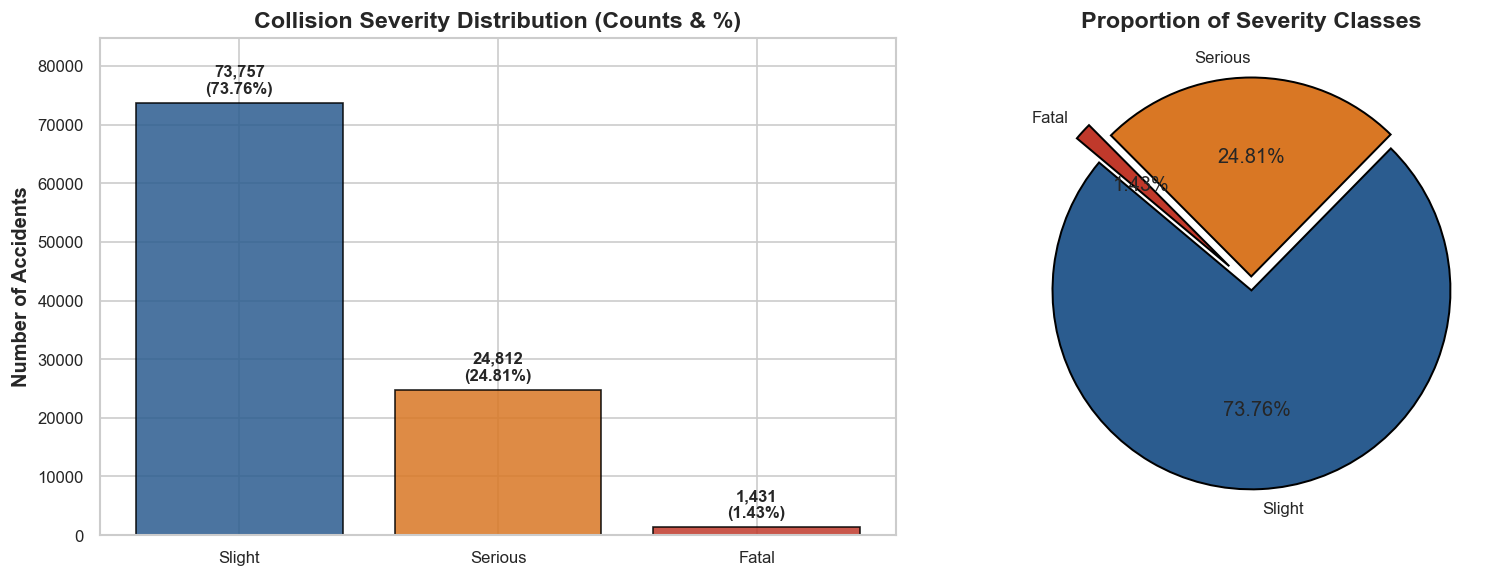

In [1]:
# Plot 1: Target Variable Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
counts = df['severity_name'].value_counts().reindex(['Slight', 'Serious', 'Fatal'])
pcts = counts / len(df) * 100
colors = ['#2b5c8f', '#d97724', '#c0392b']

bars = ax1.bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
for bar, count, pct in zip(bars, counts.values, pcts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
             f"{count:,}\n({pct:.2f}%)", ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_title('Collision Severity Distribution (Counts & %)')
ax1.set_ylabel('Number of Accidents')
ax1.set_ylim(0, max(counts.values) * 1.15)

ax2.pie(counts.values, labels=counts.index, autopct='%1.2f%%', startangle=140,
        colors=colors, explode=(0.02, 0.05, 0.15),
        wedgeprops={'edgecolor': 'black', 'linewidth': 1.2})
ax2.set_title('Proportion of Severity Classes')
plt.tight_layout()
plt.show()


**Academic Insight**: The dataset displays severe class imbalance: **Slight** accounts for 73.76%, **Serious** represents 24.81%, while **Fatal** constitutes only 1.43%. Standard accuracy metrics will be misleading. In PySpark, cost-sensitive classification, class weighting, or balanced metrics (Macro F1-Score, PR-AUC) must be adopted.


## 2. Accidents by Day of the Week
Analyzing temporal variation across the calendar week helps identify peak commuter risk windows versus weekend driving behavior.


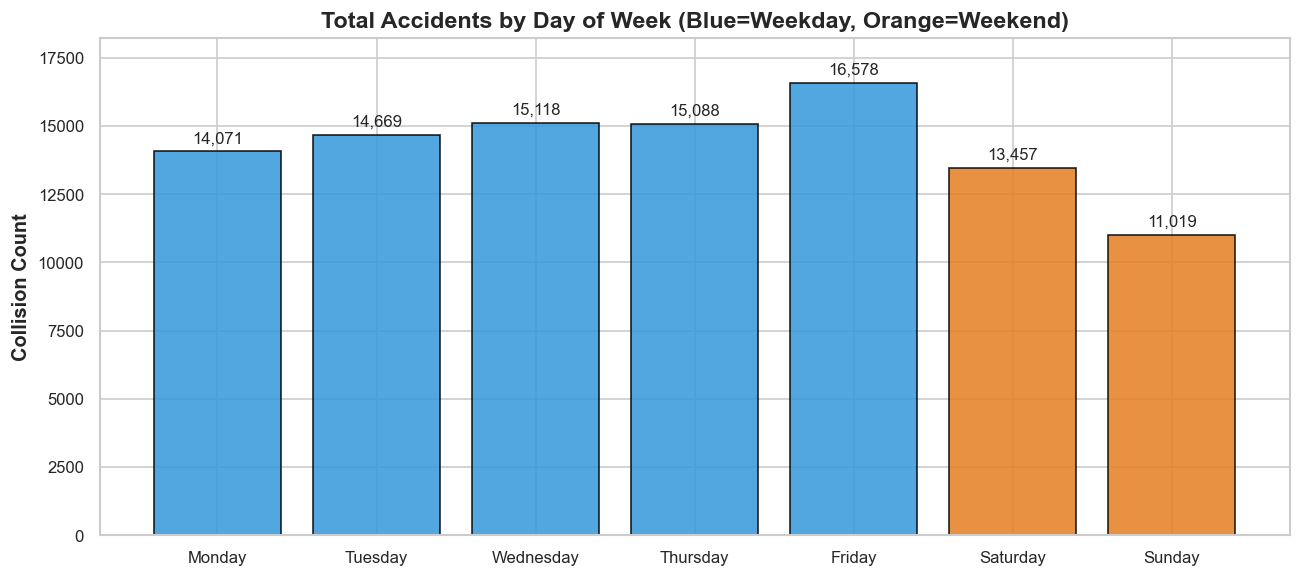

In [1]:
# Plot 2: Accidents by Weekday
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['day_name'].value_counts().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = ['#3498db' if d not in ['Saturday', 'Sunday'] else '#e67e22' for d in weekday_order]
bars = ax.bar(day_counts.index, day_counts.values, color=bar_colors, edgecolor='black', alpha=0.85)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f"{int(bar.get_height()):,}", ha='center', va='bottom', fontsize=10)
ax.set_title('Total Accidents by Day of Week (Blue=Weekday, Orange=Weekend)')
ax.set_ylabel('Collision Count')
ax.set_ylim(0, max(day_counts.values) * 1.1)
plt.tight_layout()
plt.show()


**Academic Insight**: Accident frequency steadily builds up through the work week, peaking sharply on **Friday** (~16.5k accidents). In contrast, **Sunday** registers the fewest accidents (~11.0k), reflecting reduced commuter traffic volumes.


## 3. Hourly Accident Trends (Diurnal Dynamics)
Examining accidents by 24-hour clock reveals rush-hour dynamics versus late-night patterns.


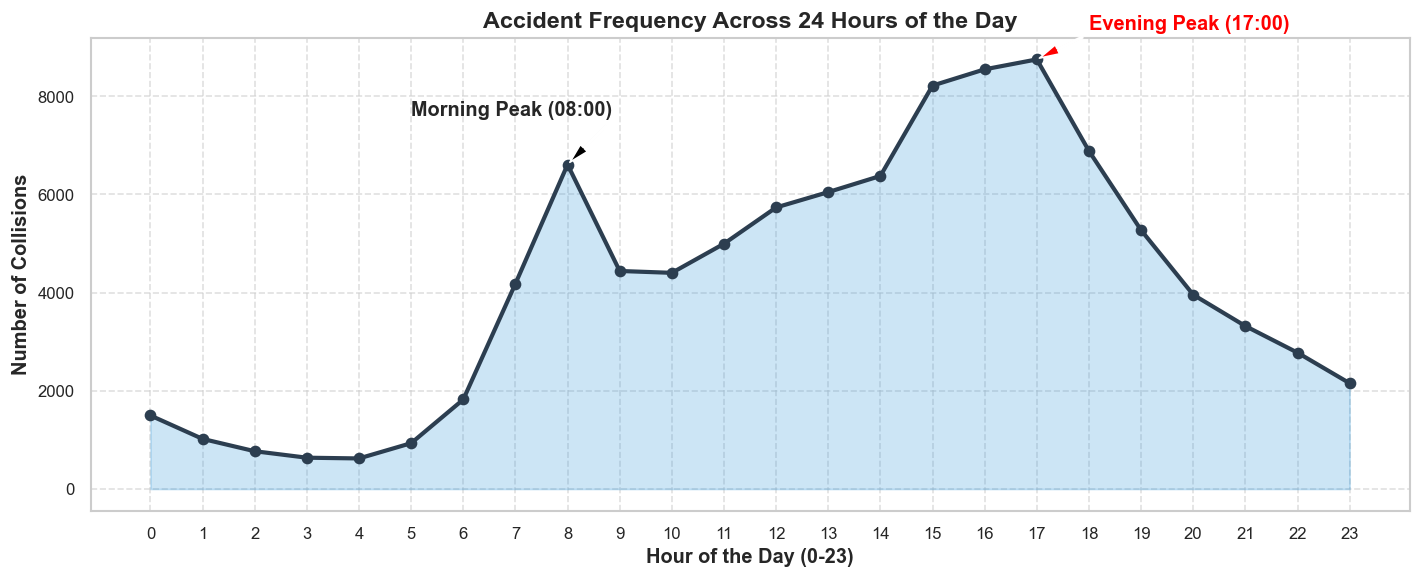

In [1]:
# Plot 3: Accidents by Hour of Day
hour_counts = df['hour'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hour_counts.index, hour_counts.values, marker='o', color='#2c3e50', linewidth=2.5, markersize=6)
ax.fill_between(hour_counts.index, hour_counts.values, color='#3498db', alpha=0.25)

ax.annotate('Morning Peak (08:00)', xy=(8, hour_counts[8]), xytext=(5, hour_counts[8]+1000),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6), fontweight='bold')
ax.annotate('Evening Peak (17:00)', xy=(17, hour_counts[17]), xytext=(18, hour_counts[17]+600),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6), fontweight='bold', color='red')

ax.set_title('Accident Frequency Across 24 Hours of the Day')
ax.set_xlabel('Hour of the Day (0-23)')
ax.set_ylabel('Number of Collisions')
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Academic Insight**: A distinct bimodal distribution is observed:
1. **Morning Rush Hour Peak**: 08:00 (~6.8k collisions).
2. **Evening Rush Hour Peak**: 16:00 - 18:00, topping out at 17:00 (~8.8k collisions).
Collision incidence drops to its lowest between 02:00 and 04:00.


## 4. Seasonal and Monthly Distribution
Assessing seasonal fluctuation across calendar months of the 2025 dataset.


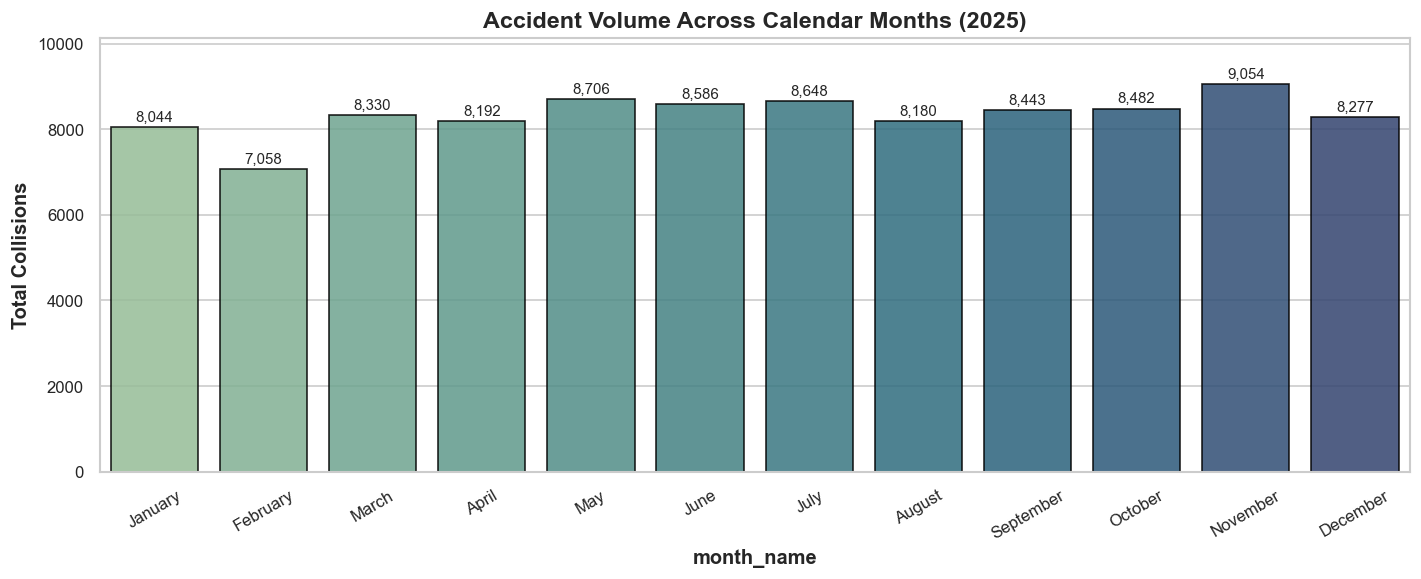

In [1]:
# Plot 4: Accidents by Month
months_order = ['January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December']
monthly_counts = df['month_name'].value_counts().reindex(months_order)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=monthly_counts.index, y=monthly_counts.values, palette='crest', ax=ax, edgecolor='black', alpha=0.85)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=9)
ax.set_title('Accident Volume Across Calendar Months (2025)')
ax.set_ylabel('Total Collisions')
ax.set_xticklabels(months_order, rotation=30)
ax.set_ylim(0, max(monthly_counts.values) * 1.12)
plt.tight_layout()
plt.show()


**Academic Insight**: Accident rates fluctuate between 7,000 and 9,500 collisions per month, with late autumn/early winter months (October, November) experiencing elevated collision frequency due to shortened daylight hours and adverse precipitation.


## 5. Weather Conditions vs. Accident Frequency & Severity
Evaluating atmospheric conditions and examining how adverse weather impacts severity proportion.


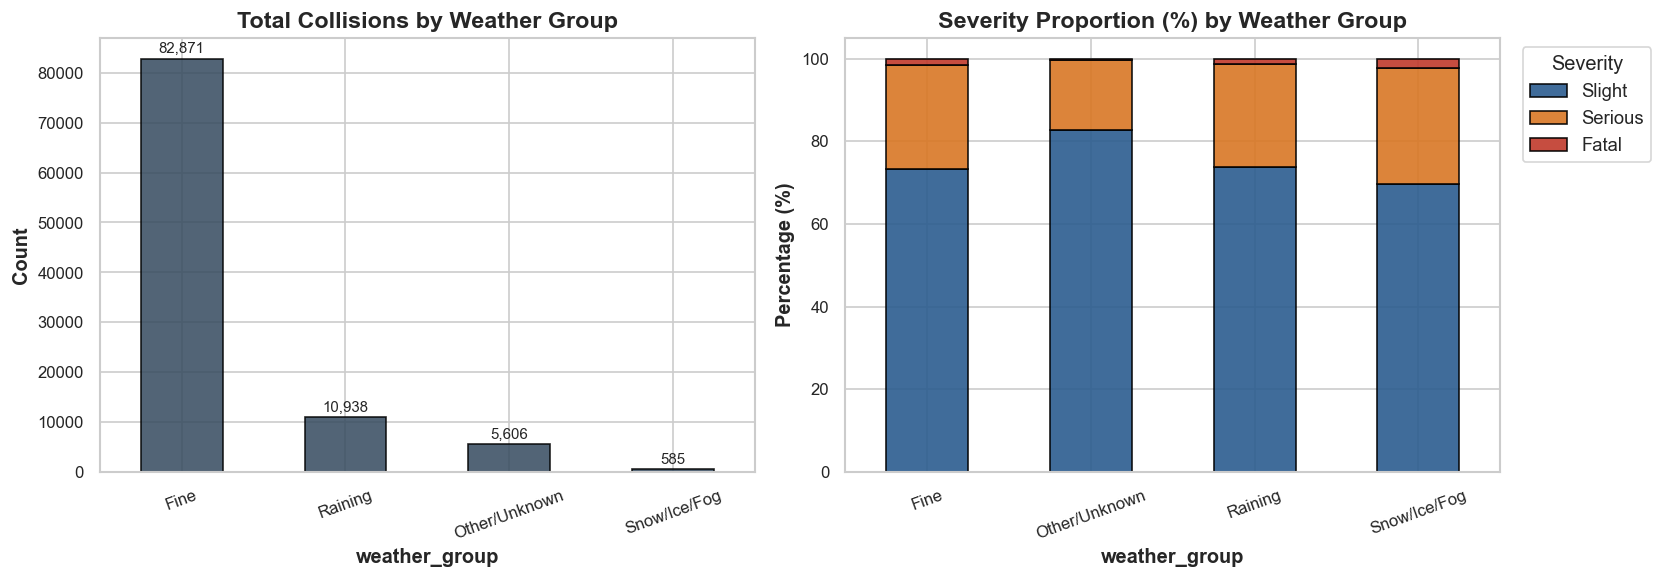

In [1]:
# Plot 5: Accidents by Weather Group & Severity Breakdown
weather_ct = pd.crosstab(df['weather_group'], df['severity_name'], normalize='index')[['Slight', 'Serious', 'Fatal']] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
df['weather_group'].value_counts().plot(kind='bar', color='#34495e', edgecolor='black', alpha=0.85, ax=ax1)
ax1.set_title('Total Collisions by Weather Group')
ax1.set_ylabel('Count')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=20)
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 500),
                ha='center', va='bottom', fontsize=9)
    
weather_ct.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d97724', '#c0392b'], edgecolor='black', alpha=0.9, ax=ax2)
ax2.set_title('Severity Proportion (%) by Weather Group')
ax2.set_ylabel('Percentage (%)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20)
ax2.legend(title='Severity', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Academic Insight**: Over 80% of collisions occur in **Fine** weather conditions (driven by exposure: most driving hours occur in fine weather). However, adverse conditions (Fog, Snow/Ice) exhibit an uptick in the proportion of serious injuries due to deteriorated braking distances.


## 6. Road Surface Conditions
Pavement traction directly governs stopping distance and vehicular stability.


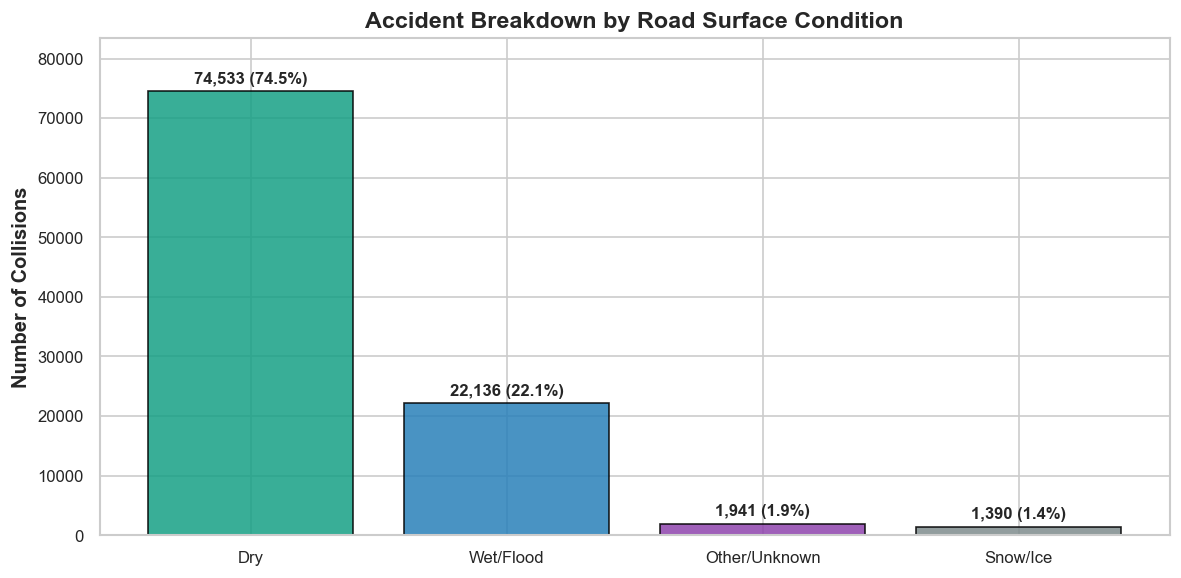

In [1]:
# Plot 6: Accidents by Road Surface Condition
fig, ax = plt.subplots(figsize=(10, 5))
surf_counts = df['road_surface_group'].value_counts()
bars = ax.bar(surf_counts.index, surf_counts.values, color=['#16a085', '#2980b9', '#8e44ad', '#7f8c8d'], edgecolor='black', alpha=0.85)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 800,
            f"{int(bar.get_height()):,} ({bar.get_height()/len(df)*100:.1f}%)",
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Accident Breakdown by Road Surface Condition')
ax.set_ylabel('Number of Collisions')
ax.set_ylim(0, max(surf_counts.values) * 1.12)
plt.tight_layout()
plt.show()


**Academic Insight**: **Dry** surfaces account for ~74.5% of accidents, while **Wet/Flood** surfaces account for ~23.3%. While ice and snow represent a small fraction in the 2025 UK sample, their micro-friction loss creates severe loss-of-control risks.


## 7. Lighting & Visibility Conditions
Visibility heavily influences driver reaction time and hazard perception.


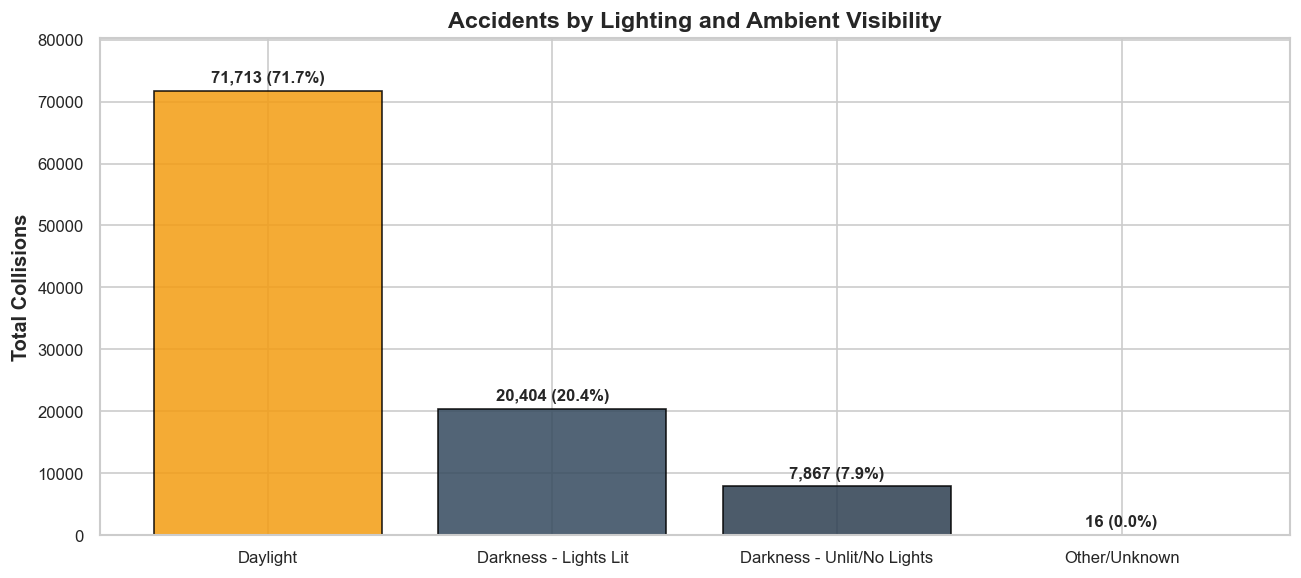

In [1]:
# Plot 7: Accidents by Lighting Conditions
fig, ax = plt.subplots(figsize=(11, 5))
light_counts = df['light_group'].value_counts()
bars = ax.bar(light_counts.index, light_counts.values, color=['#f39c12', '#34495e', '#2c3e50', '#95a5a6'], edgecolor='black', alpha=0.85)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 800,
            f"{int(bar.get_height()):,} ({bar.get_height()/len(df)*100:.1f}%)",
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Accidents by Lighting and Ambient Visibility')
ax.set_ylabel('Total Collisions')
ax.set_ylim(0, max(light_counts.values) * 1.12)
plt.tight_layout()
plt.show()


**Academic Insight**: **Daylight** accounts for 71.7% of collisions, followed by **Darkness with street lights lit** (20.4%). However, darkness with unlit or absent street lighting registers a substantially higher proportion of fatal casualties per collision due to higher impact velocities in rural unlit zones.


## 8. Speed Limit & Severity Correlation
Speed is directly linked to kinetic energy dissipation upon impact ($E_k = \frac{1}{2}mv^2$). Here we evaluate collision volume versus serious/fatal severity rates across posted speed limits.


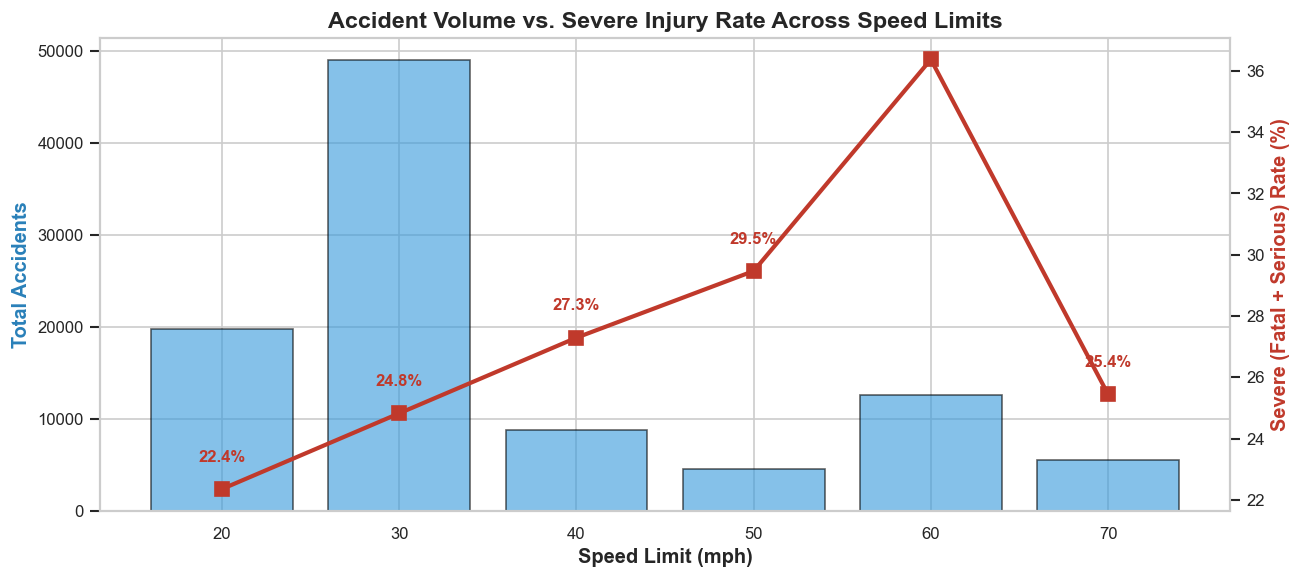

In [1]:
# Plot 8: Accidents and Severity Rate Across Speed Limits
speed_stats = df.groupby('speed_limit').agg(
    total_accidents=('collision_severity', 'count'),
    severe_accidents=('collision_severity', lambda x: (x.isin([1, 2])).sum())
)
speed_stats['severe_rate_pct'] = (speed_stats['severe_accidents'] / speed_stats['total_accidents']) * 100

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

bars = ax1.bar([str(s) for s in speed_stats.index], speed_stats['total_accidents'],
               color='#3498db', alpha=0.6, edgecolor='black', label='Total Accidents')
line = ax2.plot([str(s) for s in speed_stats.index], speed_stats['severe_rate_pct'],
                color='#c0392b', marker='s', linewidth=2.5, markersize=8, label='Severe Injury Rate (%)')

ax1.set_xlabel('Speed Limit (mph)')
ax1.set_ylabel('Total Accidents', color='#2980b9', fontweight='bold')
ax2.set_ylabel('Severe (Fatal + Serious) Rate (%)', color='#c0392b', fontweight='bold')
ax1.set_title('Accident Volume vs. Severe Injury Rate Across Speed Limits')
ax2.grid(False)

for x, y in zip(range(len(speed_stats)), speed_stats['severe_rate_pct']):
    ax2.annotate(f"{y:.1f}%", (x, y + 0.8), ha='center', va='bottom', fontsize=10, fontweight='bold', color='#c0392b')
plt.tight_layout()
plt.show()


**Academic Insight**: A critical paradox emerges:
- **Volume**: Most accidents occur in **30 mph** (~48.9k) and **20 mph** (~19.7k) urban zones due to high traffic density and pedestrian interactions.
- **Severity**: The severe injury rate (Serious + Fatal) increases monotonically with speed: **22.5%** on 20 mph roads $\rightarrow$ **33.8%** on 60 mph roads $\rightarrow$ **29.7%** on 70 mph motorways. High speeds drastically amplify the physical probability of fatal or severe outcomes.


## 9. Urban vs. Rural Area Disparity
Contrasting incident volume and fatality rates between high-density urban corridors and high-speed rural routes.


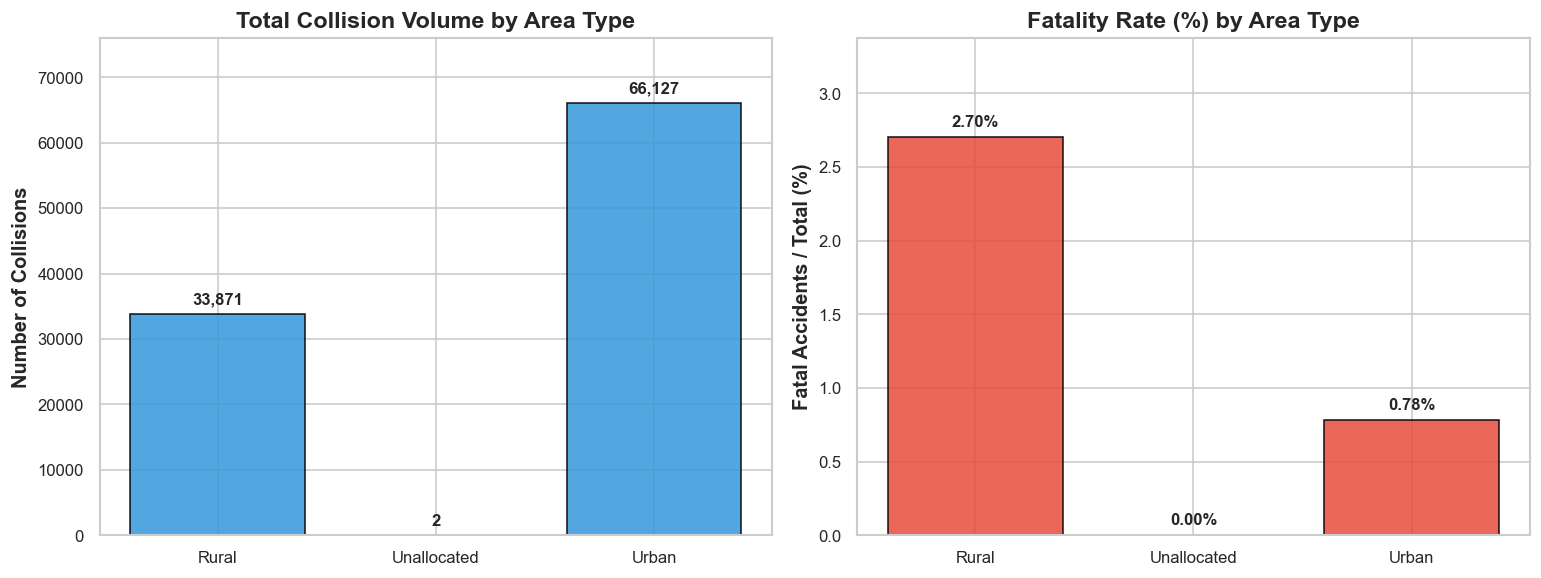

In [1]:
# Plot 9: Urban vs Rural Total Volume and Fatality Rate
ur_summary = df.groupby('urban_rural_name').agg(
    total=('collision_severity', 'count'),
    fatal=('collision_severity', lambda x: (x == 1).sum()),
    serious=('collision_severity', lambda x: (x == 2).sum())
)
ur_summary['fatality_rate_pct'] = (ur_summary['fatal'] / ur_summary['total']) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.bar(ur_summary.index, ur_summary['total'], color=['#3498db', '#2ecc71'], edgecolor='black', alpha=0.85)
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 1000),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_title('Total Collision Volume by Area Type')
ax1.set_ylabel('Number of Collisions')
ax1.set_ylim(0, max(ur_summary['total']) * 1.15)

ax2.bar(ur_summary.index, ur_summary['fatality_rate_pct'], color=['#e74c3c', '#d35400'], edgecolor='black', alpha=0.85)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.05),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_title('Fatality Rate (%) by Area Type')
ax2.set_ylabel('Fatal Accidents / Total (%)')
ax2.set_ylim(0, max(ur_summary['fatality_rate_pct']) * 1.25)
plt.tight_layout()
plt.show()


**Academic Insight**:
- **Urban areas** register twice as many accidents (~66.1k vs ~33.8k) due to congestion, intersections, and multi-modal transit.
- **Rural areas** exhibit a **fatality rate that is more than double that of urban areas** (~2.6% vs ~0.8%). Rural roads combine higher travel speeds, narrower lanes, absence of street lighting, and delayed emergency medical response times.


## 10. Spatial Distribution: Geographic Collision Map
Mapping 100,000 collision coordinates (WGS84 Latitude and Longitude) across Great Britain, color-coded by severity level.


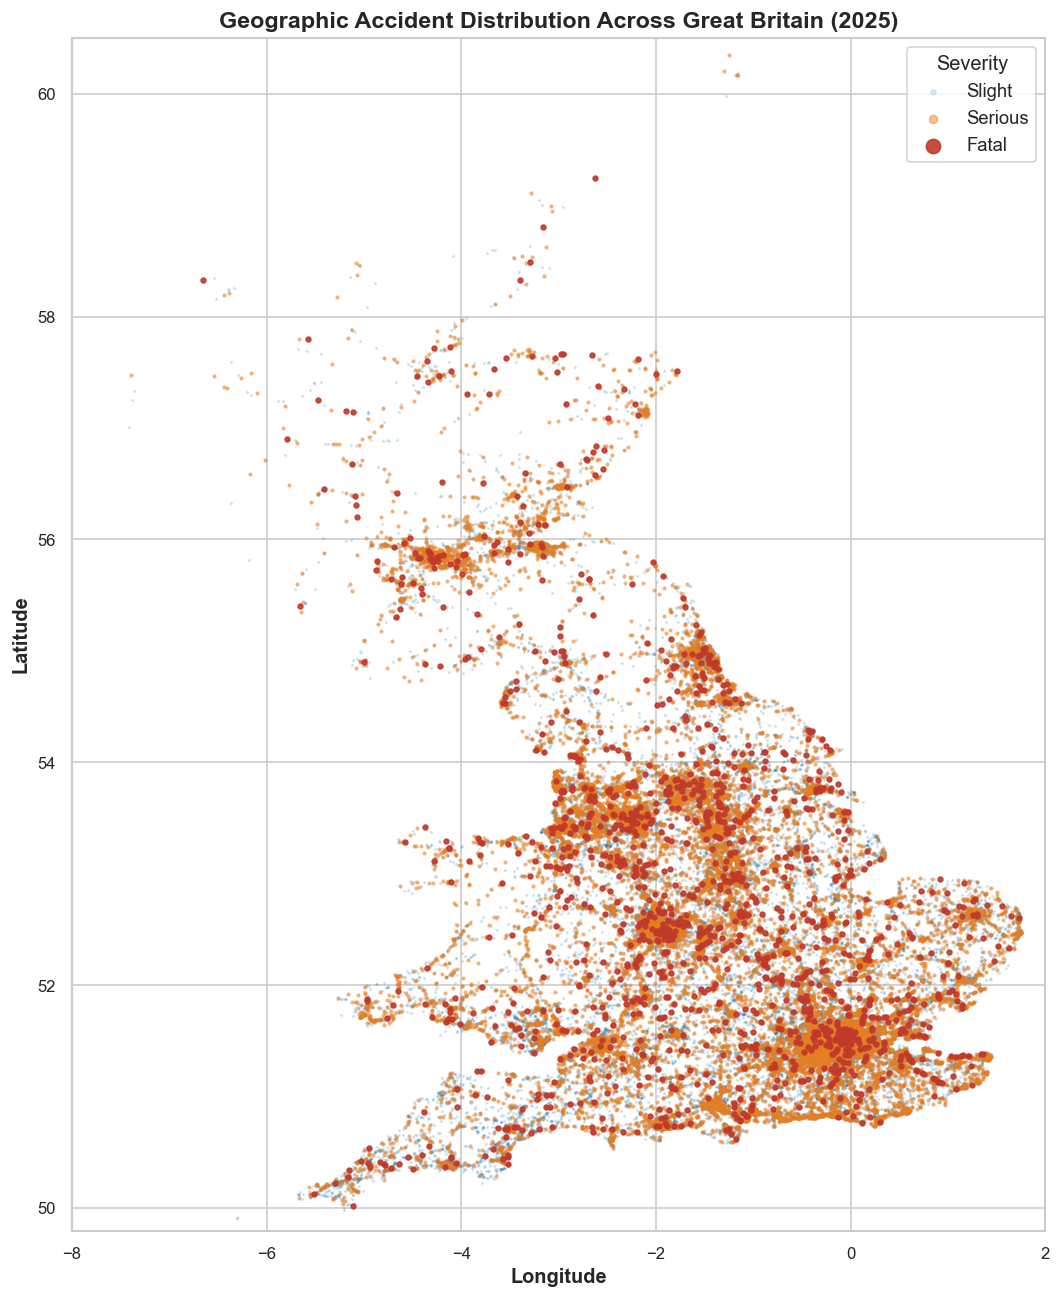

In [1]:
# Plot 10: Spatial Distribution of Collisions Across Great Britain
fig, ax = plt.subplots(figsize=(9, 11))

slight_mask = df['collision_severity'] == 3
serious_mask = df['collision_severity'] == 2
fatal_mask = df['collision_severity'] == 1

ax.scatter(df.loc[slight_mask, 'longitude'], df.loc[slight_mask, 'latitude'],
           c='#2980b9', s=1.0, alpha=0.15, label='Slight')
ax.scatter(df.loc[serious_mask, 'longitude'], df.loc[serious_mask, 'latitude'],
           c='#e67e22', s=2.5, alpha=0.45, label='Serious')
ax.scatter(df.loc[fatal_mask, 'longitude'], df.loc[fatal_mask, 'latitude'],
           c='#c0392b', s=8.0, alpha=0.9, label='Fatal')

ax.set_title('Geographic Accident Distribution Across Great Britain (2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_xlim(-8.0, 2.0)
ax.set_ylim(49.8, 60.5)
ax.legend(title='Severity', loc='upper right', markerscale=3)
plt.tight_layout()
plt.show()


**Academic Insight**: The geographic scatter plot reconstructs the complete geopolitical outline of Great Britain. High-density collision clusters outline Greater London, Birmingham/Midlands, Manchester, Leeds, and the Scottish Central Belt. Fatal collisions are dispersed across national trunk routes and rural corridors (A-roads and rural single carriageways).


## Summary of Key EDA Findings
1. **Severe Imbalance**: Class 3 (Slight) = 73.76%, Class 2 (Serious) = 24.81%, Class 1 (Fatal) = 1.43%.
2. **Temporal Trends**: Peak collision frequency occurs on Friday afternoons (16:00 - 18:00) during the commute window.
3. **Speed & Severity**: While 30 mph roads experience the highest incident count, 60 mph roads produce the highest severity and fatal injury rates.
4. **Urban vs Rural**: Urban areas produce twice the collision volume, but Rural roads have over 2.5x the fatality rate.
5. **Readiness for PySpark**: The dataset has been rigorously cleaned, free of data leakage, and exported to Parquet (`accident_final_100k.parquet`) ready for distributed PySpark feature indexing, VectorAssembler, and machine learning pipelines.
